# Project: The Supreme Intelligence 5G Transmission Coverage

<i>Konieczny Mateusz 257328 and Mikołaj Koszewski 257329, 14.11.2026 - 17.11.2026</i>

In [6]:
from scipy.spatial.distance import pdist, squareform

import matplotlib.pyplot as plt
import numpy as np

First in order to go through the solution let us try to understand the main problem with the simple visualisation - which we suppose may be helpful. Below we created functions to simply visualise the data.

In [7]:
def read_towers(file_path):
    """
    The function that reads the file and returns it's points, number of towers,number of towers to keep and dimension.

    :param file_path: string
    :return: tuple
    """
    with open(file_path, encoding="utf-8") as file:
        n, k, dimension = map(int, file.readline().split())
        points = np.loadtxt(file, dtype=int, ndmin=2)

    if dimension not in (2, 3):
        raise ValueError("The file must contain 2D or 3D points.")

    if points.shape != (n, dimension):
        raise ValueError("The coordinates do not match the file header.")

    return points, n, k, dimension


def plot_towers(file_path):
    points, n, k, dimension = read_towers(file_path)

    if dimension == 2:
        plt.figure(figsize=(7, 6))
        plt.scatter(points[:, 0], points[:, 1], color="steelblue", s=45)
        plt.xlabel("X")
        plt.ylabel("Y")
        plt.title("Towers in 2D")
        plt.axis("equal")
        plt.grid(True, alpha=0.3)

    else:
        fig = plt.figure(figsize=(8, 6))
        ax = fig.add_subplot(projection="3d")
        ax.scatter(
            points[:, 0], points[:, 1], points[:, 2],
            color="steelblue", s=45
        )
        ax.set_xlabel("X")
        ax.set_ylabel("Y")
        ax.set_zlabel("Z")
        ax.set_title("Towers in 3D")

    plt.show()

In [ ]:
plot_towers("tests/test_1.txt")

In [ ]:
plot_towers("tests/test_2.txt")

In [ ]:
plot_towers("data/miniature_3d.data")

We have an idea of a greedy algorith - we will try to take a point on it's edge. Points that are strictly to the right-bottom, right-top, left-top and left-bottom. And starting from them add the tower which distance is the longest from the chosen one. And so on, and so on. But first, we will create a function compute the matrix of distances.

In [ ]:
def distance_matrix(points):
    distances = pdist(points, metric="euclidean")
    return squareform(distances)

We have used `pdist()` function from scipy, because it is way faster than simple Numpy. Scipy calculates directly in C saving a lot of time. It also calculates distance for each pair of points once - without repetition.

In [ ]:
def greedy_algorithm(D, number_to_keep, start_index):
    selected = [start_index]
    min_distance = None

    while len(selected) < number_to_keep:  # We iterate till we get number of towers to keep
        best_index = None
        best_distance = -1

        for i in range(len(D)):  # We iterate through every tower to calculate distance
            if i in selected:
                continue

            distances = []
            for j in selected:  # Here we add distances between our candidate i and each of already selected towers
                distances.append(D[i, j])

            nearest_distance = min(distances)  # We take minimum possible distance as a reference

            if nearest_distance > best_distance:  # We want to find the maximum minimum distance from every candidate
                best_distance = nearest_distance
                best_index = i

        selected.append(best_index)

        if min_distance is None or best_distance < min_distance:
            min_distance = best_distance

    return selected, round(min_distance, 3)

This should work, now we will write a function to get as a starting index for point thats on edge.

In [ ]:
def get_starting_index(points, direction=0):
    """
    Return the index of the furthest point in the given direction.

    Directions 0 to 3 are top-right, bottom-right, top-left, bottom-left.
    In 3D, directions 0 to 3 use +z and directions 4 to 7 use -z.
    """
    dimension = points.shape[1]
    number_of_directions = 4 if dimension == 2 else 8

    if direction < 0 or direction >= number_of_directions:
        raise ValueError("Invalid starting direction.")

    x = points[:, 0]
    y = points[:, 1]

    if dimension == 2:
        scores = [x + y, x - y, -x + y, -x - y]

    if dimension == 3:
        z = points[:, 2]
        scores = [
            x + y + z, x - y + z, -x + y + z, -x - y + z,
            x + y - z, x - y - z, -x + y - z, -x - y - z,
        ]

    return int(scores[direction].argmax())

Now we think we are ready to create a test function so we'll be able to check how our algorithm will work for every file. This will be done in one function for simplicity.

In [ ]:
def print_result(selected_points, min_distance):
    for point in selected_points:
        print(*point, sep="\t")
    print(f"{min_distance}")

In [ ]:
def test_greedy_algorithm(filename: str, check=False):
    points, n, k, dimension = read_towers(filename)
    D = distance_matrix(points)
    minimum_distances = []
    selected_towers = []

    starting_point_str = ['top_right', 'bottom_right', 'top_left', 'bottom_left']
    if dimension == 3:
        starting_point_str = [
            "top_right_+z", "bottom_right_+z", "top_left_+z", "bottom_left_+z",
            "top_right_-z", "bottom_right_-z", "top_left_-z", "bottom_left_-z",
        ]

    starting_index = [get_starting_index(points, i) for i in range(len(starting_point_str))]

    # We will run the algorithm for each edge point to check which points should we choose as reference
    for i in range(len(starting_index)):
        selected, minimum_distance = greedy_algorithm(D, n - k, starting_index[i])
        minimum_distances.append(minimum_distance)
        selected_towers.append(selected)

    # If one want to see the four printed solutions the flag `check` must be switched on True
    if check:
        for i in range(len(starting_index)):
            print(starting_point_str[i])
            for k in selected_towers[i]:
                print(*points[k], sep="\t")
            print(f"{minimum_distances[i]}\n")

    # Here the function takes the index of the greatest minimum distance and returns it's point the distance
    best_distance = max(minimum_distances)
    best_index = minimum_distances.index(best_distance)
    return points[selected_towers[best_index]], best_distance

Our function is finished, now it's a big time for it to be testet on our data!

In [ ]:
best_points, best_distance = test_greedy_algorithm("tests/test_1.txt", check=True)
print_result(best_points, best_distance)

In [ ]:
best_points, best_distance = test_greedy_algorithm("tests/test_2.txt")
print_result(best_points, best_distance)

In [ ]:
best_points, best_distance = test_greedy_algorithm("tests/test_3.txt")
print_result(best_points, best_distance)

In [ ]:
best_points, best_distance = test_greedy_algorithm("data/miniature.data")
print_result(best_points, best_distance)

In [ ]:
best_points, best_distance = test_greedy_algorithm("data/miniature_3d.data", check=True)
print_result(best_points, best_distance)

In [ ]:
best_points, best_distance = test_greedy_algorithm("data/first_instance.data")
print_result(best_points, best_distance)

In [ ]:
best_points, best_distance = test_greedy_algorithm("data/first_instance_3d.data")
print_result(best_points, best_distance)

In [ ]:
best_points, best_distance = test_greedy_algorithm("data/large_instance.data")
print_result(best_points, best_distance)

In [ ]:
best_points, best_distance = test_greedy_algorithm("data/large_instance_3d.data")
print_result(best_points, best_distance)

Our algorithm worked well and fast for each of data file - we do hope POTUS and InPoczt will be satisfied from this solution.

*Konieczny Mateusz 257328 and Mikołaj Koszewski 257329*

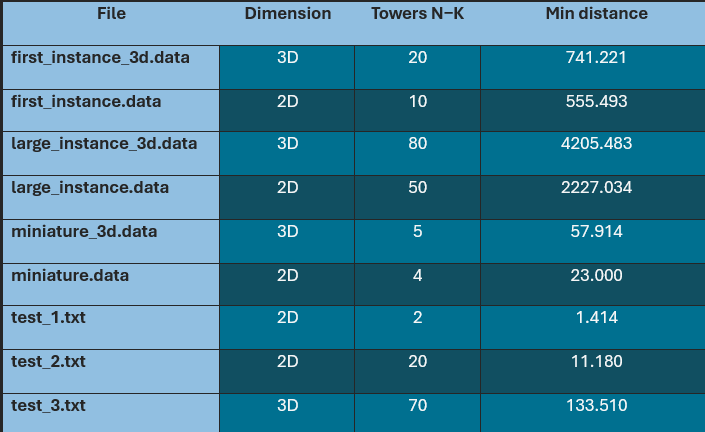

Below we have created the function for saving the files in desired format.

In [ ]:
def save_result(selected_points, min_distance, filename):
    with open(filename, "w", encoding="utf-8") as file:
        for point in selected_points:
            coordinates = []
            for coordinate in point:
                coordinates.append(str(coordinate))

            file.write("\t".join(coordinates) + "\n")

        score = round(float(min_distance), 3)
        file.write(f"{score:.3f}\n")

In [ ]:
filenames = [
    "miniature",
    "miniature_3d",
    "first_instance",
    "first_instance_3d",
    "large_instance",
    "large_instance_3d"
]

authors = "Mateusz_Konieczny_Mikolaj_Koszewski"

for name in filenames:
    best_points, best_distance = test_greedy_algorithm("data/" + name + ".data")
    save_result(
        best_points,
        best_distance,
        "solutions/" + authors + "_" + name + "_solution.txt"
    )

### TODO:

There is a need for creating sth more complex than what we have created.
1. Genetic Algorithm (opis jak dzialaja poszczegolne elementy - mutacja, krzyzowe)
2. Variable Neighbourhood Search

Wykres z wynikami, lub trajektoria wyboru celu. Histogram z greedy i tymi dwoma.
Krzywa progresji fn celu + porównanie.